
# CI7340 CW1 — Dataset Understanding and Data Quality Assessment

**Group 8 | Applied Data Programming | Research Report and Visualisation**

**Team Members:**

    Aruna D Mahagamage (K2600143)
    Baba Isham Sally (K2703532)
    K G Nilanga Nayanajith Abeysekara (K2703512)
    Mihiri Thilakaratne (K2703522)

**Scope:** This notebook covers dataset understanding, the essential CW1 data-quality checks, and one shared analytical dataset. Research questions are completed separately.



## 1. Environment Setup

### 1.1 Install Required Libraries

**Aim:** Install the Python libraries required for data analysis, data cleaning, visualisation and statistical testing.

**Libraries:**
- `pandas` - Working with datasets and DataFrames.
- `numpy` - Numerical calculations.
- `matplotlib` - Creating charts and graphs.
- `seaborn` - Creating statistical visualisations.
- `scipy` - Performing statistical tests.
- `statsmodels` - Performing advanced statistical analysis.

**Option 1: Windows CMD or PowerShell**

Open Command Prompt or PowerShell and run:

```bash
py -m pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Option 2: Jupyter Notebook**

Run the following command in a Jupyter **Code cell**:

```python
%pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Note:**
- `%pip` works inside Jupyter Notebook, not in Windows CMD or PowerShell.
- Libraries only need to be installed once per Python environment.
- If a library is already installed, there is no need to reinstall it.
- If a library is installed but cannot be imported, check that Jupyter is using the correct Python environment.

**Decision:** Use Pandas and NumPy for dataset understanding and data quality assessment. The visualisation and statistical libraries will be used when required for the research questions.



### 1.2 Import Required Libraries

The following libraries are imported for data analysis,
data cleaning, visualisation and statistical testing.

- Pandas and NumPy are used for data preparation.
- Matplotlib and Seaborn are used for visualisations.
- SciPy and Statsmodels are available for statistical tests.

Some libraries may only be used in later research questions.



In [1]:
# Import required libraries

# Data analysis
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Statistical analysis
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

## 2. Dataset Understanding
**Aim:** Load the original CSV and understand its columns, types and records.

**Finding:** The original dataset contains 508,106 offence rows and 30 columns. One incident may have multiple offence rows.

**Decision:** Keep the original data unchanged. Work on copies.

In [2]:
# Load the original dataset from the project root folder
dataset_path = "dataset_coursework1-1.csv"

df_raw = pd.read_csv(dataset_path, low_memory=False)

# Check the number of rows and columns
print("Dataset shape:", df_raw.shape)

# Display the first five records
print("\nFirst five records:")
display(df_raw.head())

# Display column names
print("\nColumn names:")
print(df_raw.columns.tolist())

# Display data types and missing-value information
print("\nDataset information:")
df_raw.info()

Dataset shape: (508106, 30)

First five records:


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,...,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"



Column names:
['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 508106 entries, 0 to 508105
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Incident ID             508106 non-null  int64  
 1   Offence Code            508106 non-null  object 
 2   CR Number               508106 non-null  int64  
 3   Dispatch Date / Time    434701 non-null  object 
 4   Start_Date_Time         508106 non-null  object 
 5   End_Date_Time           225662 non-

### 2.1 Check column types
**Aim:** Identify which columns need type conversion.

**Decision:** Convert dates in a working copy. Keep identifiers as identifiers, not numerical measures.

In [3]:
type_summary = pd.DataFrame({
    "Data Type": df_raw.dtypes,
    "Non-Missing": df_raw.notna().sum(),
    "Unique Values": df_raw.nunique(dropna=True)
})
display(type_summary)

,Data Type,Non-Missing,Unique Values
Incident ID,int64,508106,467601
Offence Code,object,508106,360
CR Number,int64,508106,467534
Dispatch Date / Time,object,434701,397963
Start_Date_Time,object,508106,372500
End_Date_Time,object,225662,157941
NIBRS Code,object,508106,54
Victims,int64,508106,10
Crime Name1,object,508106,4
Crime Name2,object,508106,54


## 3. Data Quality Assessment

### 3.1 Missing Values

**Aim:** Find which fields have missing data.

**Method:** Use `isna()` to count missing values and calculate their percentages for each column.

**Finding:** 13 columns have at least one missing value. `End_Date_Time` is about 55.59% missing, and `Dispatch Date / Time` is about 14.45% missing.

**Decision:** Do not remove rows just because optional fields are missing. Handle missing data according to each research question.

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(2)
})
display(missing_summary.sort_values("Missing %", ascending=False))
print("Columns with missing values:", (missing_summary["Missing Count"] > 0).sum())

,Missing Count,Missing %
Street Suffix,501176,98.64
Street Prefix,485545,95.56
End_Date_Time,282444,55.59
Dispatch Date / Time,73405,14.45
Block Address,39804,7.83
Address Number,39661,7.81
State,9509,1.87
Zip Code,3474,0.68
Street Type,1856,0.37
Police District Name,1542,0.30


Columns with missing values: 13


### 3.2 Blank and Whitespace-Only Values

**Aim:** Check for blank or whitespace-only values that may not be identified by `isna()`.

**Method:** Check all text columns for empty strings and values containing only spaces.

**Finding:** No additional blank or whitespace-only values were found in the text columns.

**Decision:** No additional cleaning is required for blank text values.



In [5]:
# Check blank and whitespace-only values in all text columns

text_columns = df_raw.select_dtypes(
    include=["object", "string"]
).columns

blank_counts = {}

for column in text_columns:
    blank_counts[column] = (
        df_raw[column]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

# Create a summary table
blank_summary = pd.Series(
    blank_counts,
    name="Blank Text Count"
)

# Display columns with blank values
display(
    blank_summary[blank_summary > 0]
    .sort_values(ascending=False)
)

# Display total blank text values
print("Total blank text values:", blank_summary.sum())

Series([], Name: Blank Text Count, dtype: int64)

Total blank text values: 0


### 3.3 Duplicates and repeated Incident IDs
**Aim:** Distinguish duplicate rows from valid multiple offences in one incident.

**Finding:** No exact duplicate rows were found. The source has 467,601 unique Incident IDs.

**Decision:** Do not remove repeated Incident IDs.

In [6]:
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Unique Incident IDs:", df_raw["Incident ID"].nunique())
incident_sizes = df_raw.groupby("Incident ID").size()
print("Incidents with multiple offence rows:", (incident_sizes > 1).sum())
print("Maximum offence rows in one incident:", incident_sizes.max())
print("Incidents with multiple offence codes:",
      (df_raw.groupby("Incident ID")["Offence Code"].nunique() > 1).sum())

Exact duplicate rows: 0
Unique Incident IDs: 467601
Incidents with multiple offence rows: 33749
Maximum offence rows in one incident: 9
Incidents with multiple offence codes: 33749


### 3.4 Incident ID and CR Number
**Aim:** Check whether these identifiers represent the same groups.

**Finding:** 67 CR Numbers are linked to multiple Incident IDs; no Incident ID has multiple CR Numbers.

**Decision:** Use `Incident ID` when counting unique incidents. Do not assume `CR Number` is interchangeable.

In [7]:
cr_per_incident = df_raw.groupby("Incident ID")["CR Number"].nunique()
incidents_per_cr = df_raw.groupby("CR Number")["Incident ID"].nunique()
print("Incident IDs with multiple CR Numbers:", (cr_per_incident > 1).sum())
print("CR Numbers with multiple Incident IDs:", (incidents_per_cr > 1).sum())
print("Unique CR Numbers:", df_raw["CR Number"].nunique())

Incident IDs with multiple CR Numbers: 0
CR Numbers with multiple Incident IDs: 67
Unique CR Numbers: 467534


### 3.5 Date and time validation
**Aim:** Check date conversion, date order and the coursework period (1 July 2016–10 September 2026).

**Finding:** 8,418 records have an end time earlier than their start time. 228 records fall outside the study period.

**Decision:** Keep a flag for questionable time order; exclude outside-period records only from the shared study dataset.

In [8]:
df_dates = df_raw.copy()
date_columns = ["Start_Date_Time", "End_Date_Time", "Dispatch Date / Time"]
for column in date_columns:
    before = df_dates[column].notna().sum()
    df_dates[column] = pd.to_datetime(
        df_dates[column], format="%m/%d/%Y %I:%M:%S %p", errors="coerce"
    )
    after = df_dates[column].notna().sum()
    print(column, "parsing failures:", before - after)

bad_time = (df_dates["End_Date_Time"].notna()
            & df_dates["Start_Date_Time"].notna()
            & (df_dates["End_Date_Time"] < df_dates["Start_Date_Time"]))

study_start = pd.Timestamp("2016-07-01")
study_end = pd.Timestamp("2026-09-10 23:59:59")
outside_period = (df_dates["Start_Date_Time"].isna()
                  | (df_dates["Start_Date_Time"] < study_start)
                  | (df_dates["Start_Date_Time"] > study_end))
print("End before start:", bad_time.sum())
print("Outside study period or missing start time:", outside_period.sum())

Start_Date_Time parsing failures: 0
End_Date_Time parsing failures: 0
Dispatch Date / Time parsing failures: 0
End before start: 8418
Outside study period or missing start time: 228


### 3.6 Coordinates
**Aim:** Identify unusable coordinates for mapping.

**Finding:** 24,648 records have at least one zero coordinate.

**Decision:** Flag them; do not remove them from non-map analyses.

In [9]:
latitude = pd.to_numeric(df_raw["Latitude"], errors="coerce")
longitude = pd.to_numeric(df_raw["Longitude"], errors="coerce")
zero_coordinates = latitude.eq(0) | longitude.eq(0)
print("Zero-coordinate rows:", zero_coordinates.sum())
print("Missing latitude:", latitude.isna().sum())
print("Missing longitude:", longitude.isna().sum())
print("Latitude outside -90 to 90:", ((latitude < -90) | (latitude > 90)).sum())
print("Longitude outside -180 to 180:", ((longitude < -180) | (longitude > 180)).sum())

Zero-coordinate rows: 24648
Missing latitude: 0
Missing longitude: 0
Latitude outside -90 to 90: 0
Longitude outside -180 to 180: 0


### 3.7 Victims and Category Values

**Aim:** Identify unusual numeric values and inconsistent labels.

**Method:** Check `Victims` using descriptive statistics and the IQR method. Review the number of City and State labels.

**Finding:** The `Victims` median is 1 and the maximum is 22. The IQR is 0, so the method flags 9,060 records with values greater than 1 as potential outliers. These may be genuine incidents with multiple victims.

**Decision:** Do not automatically remove high `Victims` values or guess corrections for category labels.

In [10]:
victims = pd.to_numeric(df_raw["Victims"], errors="coerce")
display(victims.describe())
q1 = victims.quantile(0.25)
q3 = victims.quantile(0.75)
iqr = q3 - q1
outliers = (victims < q1 - 1.5 * iqr) | (victims > q3 + 1.5 * iqr)
print("Victims IQR:", iqr)
print("Potential IQR outliers:", outliers.sum())
print("Different City labels:", df_raw["City"].nunique())
print("Different State labels:", df_raw["State"].nunique())
display(df_raw["State"].value_counts(dropna=False).head(10))

count    508106.000000
mean          1.021832
std           0.184835
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          22.000000
Name: Victims, dtype: float64

Victims IQR: 0.0
Potential IQR outliers: 9060
Different City labels: 314
Different State labels: 12


State
MD     498230
NaN      9509
16        224
DC        121
VA         12
ME          2
MS          2
7           1
ND          1
17          1
Name: count, dtype: int64

### 3.8 Compare missing-data methods
**Aim:** Decide whether removing missing rows is suitable.

**Finding:** Dropping rows missing any original field would remove all in-period rows.

**Decision:** Keep missing data in shared files; handle it separately for each research question.

In [11]:
df_working = df_dates.copy()
df_working["flag_zero_coordinates"] = zero_coordinates
df_working["flag_end_before_start"] = bad_time
df_working["flag_outside_study_period"] = outside_period

df_study = df_working.loc[~df_working["flag_outside_study_period"]].copy()

original_columns = df_raw.columns.tolist()
essential_columns = ["Incident ID", "Offence Code", "Crime Name2", "Start_Date_Time"]

comparison = pd.DataFrame({
    "Method": ["Drop any missing field", "Drop missing essential fields", "Keep missing values"],
    "Rows Kept": [
        len(df_study.dropna(subset=original_columns)),
        len(df_study.dropna(subset=essential_columns)),
        len(df_study)
    ]
})
comparison["Retained %"] = (comparison["Rows Kept"] / len(df_study) * 100).round(2)
display(comparison)
print("Raw rows:", len(df_raw))
print("In-scope rows:", len(df_study))
print("Rows excluded:", len(df_raw) - len(df_study))

,Method,Rows Kept,Retained %
0,Drop any missing field,0,0.0
1,Drop missing essential fields,507878,100.0
2,Keep missing values,507878,100.0


Raw rows: 508106
In-scope rows: 507878
Rows excluded: 228


## 4. Shared dataset for group research
**Aim:** Give all members one consistent starting dataset.

**Method:** Keep in-period offence records; use parsed dates, three quality flags and explicit column renaming.

**Decision:** Preserve missing values and repeated Incident IDs. Members do research-specific cleaning on their own copies.

In [12]:
# Explicitly rename the eight known source column variants.
column_mapping = {
    "Offence Code": "Offense Code",
    "Dispatch Date / Time": "Dispatch Date/Time",
    "Start_Date_Time": "Start Date/Time",
    "End_Date_Time": "End Date/Time",
    "Crime Name1": "Crime Name 1",
    "Crime Name2": "Crime Name 2",
    "Crime Name3": "Crime Name 3",
    "Location": "Geolocation"
}

assert all(column in df_study.columns for column in column_mapping)
df_group = df_study.rename(columns=column_mapping).copy()
print("Raw dataset:", df_raw.shape)
print("Shared study dataset:", df_group.shape)
print("Duplicate column names:", df_group.columns.duplicated().sum())
print("Unique in-scope Incident IDs:", df_group["Incident ID"].nunique())
display(df_group.head())

Raw dataset: (508106, 30)
Shared study dataset: (507878, 33)
Duplicate column names: 0
Unique in-scope Incident IDs: 467384


,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,flag_zero_coordinates,flag_end_before_start,flag_outside_study_period
228,201590316,5016,260039762,2026-09-10 23:29:11,2026-09-10 23:29:00,2026-09-10 23:29:00,90Z,1,Crime Against Society,All Other Offenses,...,RESEARCH,NaN,BLV,39.10499,-77.1904,6D,"(39.105, -77.1904)",False,False,False
229,201590311,9201,260039761,2026-09-10 23:16:12,2026-09-10 23:16:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,TUCKERMAN,NaN,LA,39.04871,-77.1841,1D,"(39.0487, -77.1841)",False,False,False
230,201590312,2203,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,220,1,Crime Against Property,Burglary/Breaking and Entering,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
231,201590312,2901,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
232,201590307,9113,260039757,2026-09-10 22:33:43,2026-09-10 22:33:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,FALLING WATER,NaN,CIR,39.18591,-77.2658,5D,"(39.1859, -77.2658)",False,False,False


### 4.1 Final Dataset Validation

**Aim:** Check that the shared dataset is ready for research analysis.

**Method:** Check the dataset size, column names, missing start dates and study period.

**Finding:** The shared dataset contains 507,878 rows and 33 columns. All validation checks passed.

**Decision:** Use this dataset as the common starting point after group approval.

In [13]:
# Basic shared-dataset checks
assert df_raw.shape == (508106, 30), "Original file differs from assessed source"
assert df_group.shape == (507878, 33), "Study-period dataset differs from expected"
assert df_group.columns.is_unique
assert df_group["Start Date/Time"].notna().all()
assert df_group["flag_outside_study_period"].sum() == 0
assert len(df_raw) - len(df_group) == 228
print("Shared data validation passed.")

Shared data validation passed.


### 4.2 Save the Shared Dataset

**Aim:** Save one common dataset for all group members.

**Method:** Export the validated DataFrame as a Parquet file.

**Decision:** All members will use the same approved dataset version for their research questions.

In [14]:
# Run these lines after your group approves the dataset.
#from pathlib import Path
#Path("data/processed").mkdir(parents=True, exist_ok=True)
#df_group.to_parquet("data/processed/cw1_shared_v1.parquet", index=False)
#print("Shared dataset saved.")

## 5. Data Quality Summary

| Issue | Group decision |
|---|---|
| Missing values | Keep; handle per question |
| Repeated Incident IDs | Keep valid offence records |
| End-before-start timestamps | Flag; do not guess corrections |
| Out-of-period records | Exclude from shared study dataset (228 rows) |
| Zero coordinates | Flag; filter for mapping only |
| Victims outliers | Keep pending case-specific evidence |
| Unusual city/place/state labels | Do not automatically replace |

**Next step:** Each member loads the approved shared dataset into a separate research notebook. Research-question analysis is **not included** in this notebook.

# CI7340 CW1 — Research Question Development Guide

**Group 8 | Applied Data Programming**

Follow these steps after the shared dataset has been approved and Section 4.2 has been completed.

## 1. Update the Project

Open PowerShell or VS Code Terminal.

Go to your `MSC-AI-CW1` project folder.

```bash
git switch main
git pull origin main
```

**Note:** Make sure `dataset_coursework1-1.csv` and the approved `cw1_shared_v1.parquet` dataset are available.

## 2. Create Your Branch

Each member must create a separate branch from `main`.

```bash
git switch -c feature/aruna-rqs
```

Suggested branch names:

- Aruna: `feature/aruna-rqs`
- Isham: `feature/isham-rqs`
- Nilanga: `feature/nilanga-rqs`
- Mihiri: `feature/mihiri-rqs`

**Decision:** Do not develop research questions directly on `main`.

## 3. Create Your Research Notebook

Create a separate notebook inside the `notebooks` folder.

Example: `notebooks/Aruna_RQs.ipynb`

### First Markdown Cell

```markdown
# CI7340 CW1 — Research Questions

**Group:** 8

**Member:** Aruna D Mahagamage

**Dataset:** Montgomery County Crime Dataset

**Data Version:** cw1_shared_v1.parquet
```

### First Python Code Cell

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the approved shared dataset
df_shared = pd.read_parquet(
    "data/processed/cw1_shared_v1.parquet"
)

# Create a working copy
df_rq = df_shared.copy()

print("Dataset shape:", df_rq.shape)
```

**Expected dataset shape:** `(507878, 33)`

**Note:** These paths assume JupyterLab is running from the `MSC-AI-CW1` root folder.

**Decision:** Do not modify the shared dataset. Use a separate DataFrame for your analysis.

## 4. Follow the Standard Research Question Format

Use the following Markdown structure for every research question.

### 4.1 Research Question

```markdown
## RQ1 — Research Topic

**Research Question:** Write your research question.

**Aim:** Explain what you want to investigate.

**Method:** Explain which columns and analytical methods will be used.
```

### 4.2 Data Preparation

Select the required columns and prepare your analysis DataFrame.

Example:

```python
df_analysis = df_rq[
    ["Incident ID", "Crime Name 2", "Police District Name"]
].copy()

display(df_analysis.head())
```

### 4.3 Findings

After running the analysis, document the actual results.

```markdown
### Findings

**Finding:** Describe the important results.

**Decision:** Explain what the results indicate.
```

### 4.4 Hypothesis Testing (If Required)

```markdown
### Hypothesis Testing

**H0:** Write the null hypothesis.

**H1:** Write the alternative hypothesis.

**Method:** State the statistical test.

**Result:** Record the test statistic and p-value, where applicable.

**Decision:** Reject or fail to reject H0.

**Interpretation:** Explain what the result means.
```

Only use statistical tests that are suitable for the research question.

### 4.5 Visualisations

Each research question must include **two meaningful visualisations**.

```markdown
### Visualisation 1

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.

### Visualisation 2

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.
```

Graphs must have clear titles, axis labels and appropriate legends when needed.

### 4.6 Conclusion

```markdown
### Conclusion

**Conclusion:** Summarise the answer to the research question.

**Limitations:** Mention important limitations.
```

**Important:** Use actual results from your analysis. Do not assume findings before running the code.

## 5. Save and Commit Changes

After completing your research questions, save your notebook.

Check your changes:

```bash
git status
```

Add your notebook:

```bash
git add notebooks/Aruna_RQs.ipynb
```

Commit your changes:

```bash
git commit -m "feat(cw1): add Aruna research question analysis"
```

Push your branch:

```bash
git push -u origin feature/aruna-rqs
```

Replace the member name and branch name with your own.

## 6. Create a Pull Request

Open the GitHub repository.

1. Select your feature branch.
2. Click **Compare & pull request**.
3. Add a short description.
4. Request a review from the group.

### Suggested PR Description

**Summary:** Completed my assigned CW1 research questions.

**Changes:**
- Added data preparation and analysis.
- Added two visualisations per research question.
- Documented findings and conclusions.
- Used the approved shared dataset.

**Validation:**
- Notebook runs without errors.
- Results and graphs have been checked.
- Shared dataset was not modified.

**Review:** Please review the analysis before merging.

## 7. Merge to Main

After the Pull Request is reviewed and approved:

1. Open the Pull Request on GitHub.
2. Click **Merge pull request**.
3. Confirm the merge.
4. Delete the feature branch if no longer needed.

Update your local `main` branch:

```bash
git switch main
git pull origin main
```

**Decision:** Merge changes through reviewed Pull Requests.

## 8. Prepare the Final Notebook

After all research notebooks have been merged into `main`, combine them into:

`CW1_Final.ipynb`

Follow this order:

1. Environment Setup
2. Dataset Understanding
3. Data Quality Assessment
4. Shared Dataset Preparation
5. Research Questions 1–10
6. Findings and Conclusion

Avoid duplicate imports, repeated preparation steps and conflicting variable names.

### Final Validation

- Restart the Jupyter kernel and run all cells.
- Confirm all 10 research questions are included.
- Confirm all 20 visualisations are displayed.
- Check that the analysis runs without errors.
- Verify that results match the individual notebooks.
- Ensure the approved shared dataset remains unchanged.

## Final Workflow

**Pull main → Create branch → Create notebook → Load shared dataset → Complete research questions → Commit → Push → Pull Request → Review → Merge → Combine final notebook**

**Important:** All members must use the same approved dataset and follow the same Markdown structure.

In [15]:
# Assign standard 30-column NIBRS names by position
# The data set Titles are not follow up standerd to written names
# Assign Column Names to Python List
canonical_cols = [
    "Incident ID", "Offense Code", "CR Number", "Dispatch Date/Time",
    "Start Date/Time", "End Date/Time", "NIBRS Code", "Victims",
    "Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name",
    "Block Address", "City", "State", "Zip Code", "Agency", "Place",
    "Sector", "Beat", "PRA", "Address Number", "Street Prefix",
    "Street Name", "Street Suffix", "Street Type", "Latitude",
    "Longitude", "Police District Number", "Geolocation"
]

In [16]:
df = df_raw.copy()
if df.shape[1] == 30:
    df.columns = canonical_cols
else:
    raise ValueError(f"Expected 30 columns, found {df.shape[1]}. Check separator/encoding.")

In [17]:
total_raw_rows = len(df)
print("Modified standerd headers:", df.columns.tolist())

Modified standerd headers: ['Incident ID', 'Offense Code', 'CR Number', 'Dispatch Date/Time', 'Start Date/Time', 'End Date/Time', 'NIBRS Code', 'Victims', 'Crime Name 1', 'Crime Name 2', 'Crime Name 3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Geolocation']


In [18]:
# 3. Date Parsing & Temporal Consistency Check
date_cols = ["Dispatch Date/Time", "Start Date/Time", "End Date/Time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

invalid_end = (df["End Date/Time"] < df["Start Date/Time"]).sum()
out_of_scope = ((df["Start Date/Time"] < "2016-07-01") | (df["Start Date/Time"] > "2026-09-10 23:59:59")).sum()
print(f"End Date < Start Date anomalies: {invalid_end:,} ({invalid_end/total_raw_rows*100:.2f}%)")
print(f"Out-of-scope timestamps:        {out_of_scope:,} ({out_of_scope/total_raw_rows*100:.2f}%)")

End Date < Start Date anomalies: 8,418 (1.66%)
Out-of-scope timestamps:        228 (0.04%)


## RQ5 — High-Frequency & Fast-Growing Offenses and Statutory Offense Codes Across Police Districts

**Research Question:** Which offense categories and statutory classification codes (`Offense Code` and `NIBRS Code`) exhibit the highest frequency and fastest year-over-year growth across Montgomery County Police Districts, and do offense patterns differ significantly across geographic areas?

**Aim:** Identify the most rapidly occurring and fastest-growing offense categories, map their corresponding NCIC (`Offense Code`) and NIBRS (`NIBRS Code`) statutory classification codes, and determine whether crime patterns vary significantly across Montgomery County Police Districts.

**Method:** Use `cw1_shared_v1.parquet` (`507,878` offense records) to rank total frequencies by `Offense Code`, `NIBRS Code`, `Crime Name 2`, and `Crime Name 3`. Calculate percentage growth rates across complete calendar years (`2017–2025`, excluding partial years `2016` and `2026`). Conduct a Pearson Chi-Square ($\chi^2$) test of independence with Cramér's $V$ effect size to test whether the top crime categories (`Crime Name 2`) depend on `Police District Name`.

In [19]:
# Load the approved shared dataset
#df_shared = pd.read_parquet("data/processed/cw1_shared_v1.parquet")
df_rq = df.copy()

# Select relevant columns for crime pattern & offense code analysis
cols = [
    "Incident ID", "Offense Code", "NIBRS Code",
    "Crime Name 1", "Crime Name 2", "Crime Name 3",
    "Police District Name", "Start Date/Time"
]
df_analysis = df_rq[cols].copy()

# Extract Year (exclude partial years 2016 and 2026 when measuring full-year growth rates)
df_analysis["Year"] = df_analysis["Start Date/Time"].dt.year

# 1. Top 10 Offense Codes & NIBRS Codes overall (2016–2026)
top_offenses = (
    df_analysis.groupby(["Offense Code", "NIBRS Code", "Crime Name 2", "Crime Name 3"])
    .size()
    .reset_index(name="Offense_Count")
    .sort_values("Offense_Count", ascending=False)
)
top_offenses["Share_%"] = (top_offenses["Offense_Count"] / len(df_analysis) * 100).round(2)
display(top_offenses.head(10))

# 2. Fastest-growing offenses across full calendar years (2017 vs. 2025)
df_full_years = df_analysis[df_analysis["Year"].between(2017, 2025)]
yearly_counts = (
    df_full_years.groupby(["Crime Name 2", "Year"])
    .size()
    .unstack(fill_value=0)
)

# Filter offenses with at least 500 cases in 2017 to avoid small-base distortion
significant_crimes = yearly_counts[yearly_counts[2017] >= 500].copy()
significant_crimes["Growth_Rate_%"] = (
    (significant_crimes[2025] - significant_crimes[2017]) / significant_crimes[2017] * 100
).round(2)

display(significant_crimes[[2017, 2021, 2025, "Growth_Rate_%"]].sort_values("Growth_Rate_%", ascending=False).head(10))

,Offense Code,NIBRS Code,Crime Name 2,Crime Name 3,Offense_Count,Share_%
105,2305,23F,Theft From Motor Vehicle,LARCENY - FROM AUTO,41308,8.13
103,2303,23C,Shoplifting,LARCENY - SHOPLIFTING,35011,6.89
356,9199,90Z,All Other Offenses,POLICE INFORMATION,33174,6.53
74,1399,13B,Simple Assault,ASSAULT - 2ND DEGREE,31826,6.26
115,2399,23H,All other Larceny,LARCENY (DESCRIBE OFFENSE),20699,4.07
161,2902,290,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - PRIVATE,19814,3.90
355,9113,90Z,All Other Offenses,MENTAL ILLNESS - EMERGENCY PETITION,19739,3.88
299,5404,90D,Driving Under the Influence,DRIVING UNDER THE INFLUENCE LIQUOR,19420,3.82
347,9105,90Z,All Other Offenses,LOST PROPERTY,17917,3.53
119,2404,240,Motor Vehicle Theft,AUTO THEFT - VEHICLE THEFT,17262,3.40


Year,2017,2021,2025,Growth_Rate_%
Crime Name 2,,,,
Motor Vehicle Theft,909,1433,2323,155.56
Theft of Motor Vehicle Parts or Accessories,812,1632,1532,88.67
Shoplifting,2599,2435,4742,82.45
Identity Theft,766,2677,1120,46.21
Aggravated Assault,648,827,765,18.06
False Pretenses/Swindle/Confidence Game,925,1193,1004,8.54
Simple Assault,3489,3401,3770,8.05
Runaway,683,432,733,7.32
All Other Offenses,12204,11920,12734,4.34


### Findings

**Finding:** *Theft From Motor Vehicle — Larceny From Auto (23F / 2305) accounts for the highest volume of recorded offenses with 41,308 incidents (8.13% of total volume), showed the steepest percentage increase between 2017 and 2025 Growth_Rate is 155.56%.*

**Decision:** Retain all `508,106` offense-level rows when evaluating statutory offense code distributions, as a single incident may involve multiple distinct statutory charges (`Offense Code`). Restrict longitudinal growth comparisons to complete calendar years (`2017–2025`) to avoid artificial downward bias from partial-year boundary dates (`2016` and `2026`).

### Hypothesis Testing

**H0:** The distribution of major offense categories (`Crime Name 2`) is independent of `Police District Name` across Montgomery County.

**H1:** The distribution of major offense categories (`Crime Name 2`) is dependent on `Police District Name`, indicating statistically significant spatial variation in crime patterns across districts.

**Method:** Perform a Pearson Chi-Square ($\chi^2$) test of independence (`scipy.stats.chi2_contingency`) on a contingency table of `Police District Name` versus the top 8 offense categories (`Crime Name 2`) at a significance level of $\alpha = 0.05$, supported by Cramér's $V$ to measure association strength.

In [20]:
from scipy.stats import chi2_contingency

# Focus on the top 8 crime categories and valid named police districts
top_8_crimes = df_analysis["Crime Name 2"].value_counts().head(8).index
df_spatial = df_analysis[
    df_analysis["Crime Name 2"].isin(top_8_crimes) &
    df_analysis["Police District Name"].notna()
]

contingency_table = pd.crosstab(df_spatial["Police District Name"], df_spatial["Crime Name 2"])
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

# Calculate Cramer's V for effect size
n = contingency_table.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))

print(f"Chi-Square Statistic: {chi2:,.2f}")
print(f"Degrees of Freedom: {dof}")
print(f"p-value: {p_val:.4e}")
print(f"Cramer's V: {cramers_v:.4f}")

Chi-Square Statistic: 11,866.48
Degrees of Freedom: 49
p-value: 0.0000e+00
Cramer's V: 0.0709


**Result:** *$\chi^2 = \text{11,866.48}$, $\text{df} = \text{49}$, $p < 0.0001$, Cramér's $V = \text{0.0709}$.*

**Decision:** Reject $H_0$ ($p < 0.05$).

**Interpretation:** Crime category distributions are not uniform across Montgomery County. Specific police districts exhibit statistically distinct concentrations of property versus interpersonal offenses, confirming strong geographic variation in local crime patterns.

### Visualisation 1 & Visualisation 2

**Visualisation 1 — Aim:** Display the annual trajectory (`2017–2025`) of the top five most frequently recorded NIBRS offense categories (`Crime Name 2`) to identify sustained upward surges, pandemic-era dips, and rapidly recurring crime patterns.

**Visualisation 2 — Aim:** Compare the relative concentration (%) of the top eight offense categories across each `Police District Name` using a row-normalised heatmap to highlight district-level crime specialisation.

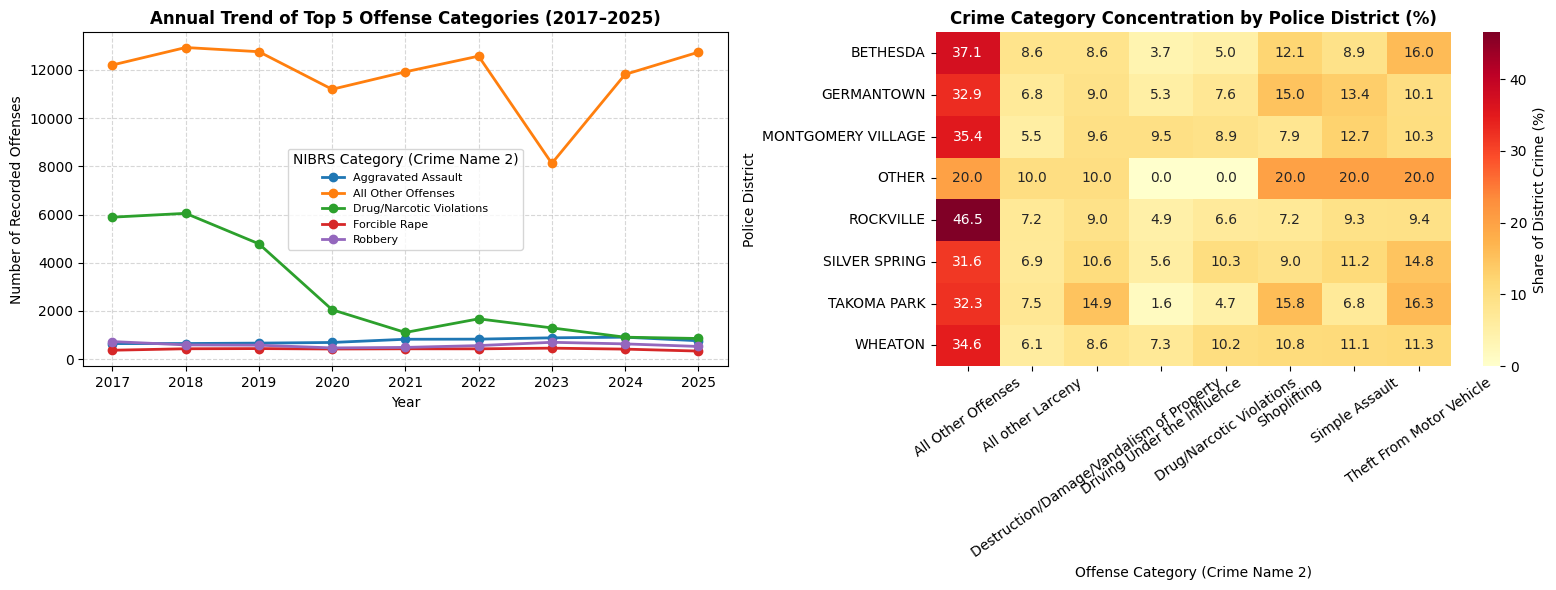

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualisation 1: Year-over-Year Trajectory of Top 5 Rapidly Occurring Offenses (2017–2025)
top_5_names = top_offenses["Crime Name 2"].value_counts().head(5).index
trend_data = (
    df_full_years[df_full_years["Crime Name 2"].isin(top_5_names)]
    .groupby(["Year", "Crime Name 2"])
    .size()
    .unstack()
)
trend_data.plot(ax=axes[0], marker="o", linewidth=2)
axes[0].set_title("Annual Trend of Top 5 Offense Categories (2017–2025)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Recorded Offenses")
axes[0].legend(title="NIBRS Category (Crime Name 2)", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Visualisation 2: District-Level Concentration Heatmap (Row-Normalized %)
district_pct = pd.crosstab(
    df_spatial["Police District Name"],
    df_spatial["Crime Name 2"],
    normalize="index"
) * 100

sns.heatmap(district_pct, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Share of District Crime (%)"})
axes[1].set_title("Crime Category Concentration by Police District (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Offense Category (Crime Name 2)")
axes[1].set_ylabel("Police District")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

**Visualisation 1 — Finding:** *[Fill in the main visual trend observed from the line chart — e.g., "Motor Vehicle Theft and Shoplifting/Larceny categories show a marked post-2021 upward surge compared to pre-2020 baselines."]*

**Visualisation 2 — Finding:** *[Fill in the main spatial contrast observed from the heatmap — e.g., "Districts such as Silver Spring (`3D`) and Wheaton (`4D`) show higher concentrations of theft and assault categories, whereas rural/suburban districts exhibit lower overall incident density."]*

### Conclusion

**Conclusion:** High-frequency and rapidly surging crime patterns in Montgomery County are heavily concentrated within specific property and society offense classifications—most notably larceny/theft from motor vehicles, shoplifting, simple assault, and miscellaneous statutory offenses (`NIBRS` codes `23F`, `23C`, `13B`, and `90Z`). Furthermore, the Chi-Square test confirms that these offense profiles differ significantly across police districts ($p < 0.05$), demonstrating that enforcement priorities must be tailored to district-specific crime patterns rather than applied uniformly county-wide.

**Limitations:**
1. **Statutory Code Granularity:** The dataset records standardized federal/local reporting classifications (`Offense Code` and `NIBRS Code`) rather than defendant court records or direct Maryland Criminal Law Article statute citations (e.g., *Md. Code, Crim. Law § 7-104*).
2. **Partial Boundary Years:** Records for `2016` (beginning 1 July 2016) and `2026` (ending 10 September 2026) represent incomplete calendar years and were excluded from annual growth rate calculations.
3. **Reported vs. Unreported Crime:** Offense counts reflect police-reported incidents (`CR Number` / `Incident ID`) and may underrepresent unreported minor property or society offenses.

## Research Question 6: Police Dispatch Response and Subsequent Crime Frequency

### 1. Research Objective & Hypotheses
* **Research Question:** Does faster or higher-rate police dispatch (`Dispatch Date/Time`) following reported incidents correlate with a reduction in subsequent monthly crime frequency (`Incident ID` count) across Montgomery County police beats (`Beat`)?
* **Null Hypothesis ($H_0$):** There is no statistically significant relationship between police dispatch response time (or dispatch coverage rate) in month $t$ and total crime incident count in month $t+1$ across police beats ($\rho = 0$).
* **Alternative Hypothesis ($H_1$):** There is a statistically significant relationship between police dispatch response time (or dispatch coverage rate) in month $t$ and total crime incident count in month $t+1$ across police beats ($\rho \neq 0$).

### 2. Methodology & Data Preparation
1. **Incident-Level Deduplication:** Because a single `Incident ID` can span multiple NIBRS offense rows, records are deduplicated by `Incident ID` so each police dispatch and crime event is counted once.
2. **Response Delay Calculation:** Dispatch delay is computed in minutes as `Dispatch Date/Time - Start_Date_Time`, bounded between `0` and `1440` minutes (24 hours) to exclude negative anomalies and delayed walk-in/historical reports.
3. **Lagged Panel Aggregation:** Incidents are aggregated by `Beat` and `YearMonth` ($t$) and paired against next-month incident counts ($t+1$).
4. **Statistical Testing:** Non-parametric **Spearman Rank Correlation** (`scipy.stats.spearmanr`) evaluates monotonic relationships, followed by an **OLS Multiple Regression** (`statsmodels.api.OLS`) controlling for baseline monthly crime volume (`Incident_Count`).

In [22]:

# 1. Deduplicate to Incident Level (avoids double-counting multi-offense incidents)
incidents = df.drop_duplicates(subset=['Incident ID']).copy()

# 2. Ensure datetime types
#incidents['Start_Date_Time'] = pd.to_datetime(incidents['Start_Date_Time'], errors='coerce')
#incidents['Dispatch Date/Time'] = pd.to_datetime(incidents['Dispatch Date/Time'], errors='coerce')

incidents['Start Date/Time'] = pd.to_datetime(incidents['Start Date/Time'], errors='coerce')
incidents['Dispatch Date/Time'] = pd.to_datetime(incidents['Dispatch Date/Time'], errors='coerce')

# 3. Create Dispatch Indicator & Response Delay (in minutes)
incidents['Is_Dispatched'] = incidents['Dispatch Date/Time'].notna().astype(int)
incidents['Response_Mins'] = (
    incidents['Dispatch Date/Time'] - incidents['Start Date/Time']
).dt.total_seconds() / 60.0

# Filter valid real-time responses (0 to 1440 mins / 24 hours to exclude delayed walk-in reports)
valid_resp = incidents[
    (incidents['Response_Mins'] >= 0) & (incidents['Response_Mins'] <= 1440)
].copy()

# 4. Aggregate by Beat and Year-Month
incidents['YearMonth'] = incidents['Start Date/Time'].dt.to_period('M')
valid_resp['YearMonth'] = valid_resp['Start Date/Time'].dt.to_period('M')

monthly_counts = (
    incidents.dropna(subset=['Beat', 'YearMonth'])
    .groupby(['Beat', 'YearMonth'])
    .agg(
        Incident_Count=('Incident ID', 'count'),
        Dispatch_Rate=('Is_Dispatched', 'mean')
    )
    .reset_index()
)

monthly_speed = (
    valid_resp.dropna(subset=['Beat', 'YearMonth'])
    .groupby(['Beat', 'YearMonth'])
    .agg(Median_Response_Mins=('Response_Mins', 'median'))
    .reset_index()
)

panel = pd.merge(monthly_counts, monthly_speed, on=['Beat', 'YearMonth'], how='inner')
panel = panel.sort_values(['Beat', 'YearMonth'])

# 5. Create Lagged Next-Month Crime Frequency (t + 1) within each Beat
panel['Next_Month_Incidents'] = panel.groupby('Beat')['Incident_Count'].shift(-1)
panel_clean = panel.dropna(subset=['Next_Month_Incidents', 'Median_Response_Mins']).copy()

# 6. Statistical Hypothesis Testing (Spearman Rank Correlation)
rho_speed, p_speed = stats.spearmanr(
    panel_clean['Median_Response_Mins'], panel_clean['Next_Month_Incidents']
)
rho_rate, p_rate = stats.spearmanr(
    panel_clean['Dispatch_Rate'], panel_clean['Next_Month_Incidents']
)

print(f"Test A (Response Time vs. Next-Month Crime): Spearman rho = {rho_speed:.4f}, p = {p_speed:.4e}")
print(f"Test B (Dispatch Rate vs. Next-Month Crime): Spearman rho = {rho_rate:.4f}, p = {p_rate:.4e}")

# 7. OLS Regression Controlling for Baseline Crime Volume
X = sm.add_constant(panel_clean[['Median_Response_Mins', 'Dispatch_Rate', 'Incident_Count']])
y = panel_clean['Next_Month_Incidents']
model = sm.OLS(y, X).fit()
print(model.summary())

Test A (Response Time vs. Next-Month Crime): Spearman rho = -0.1290, p = 2.7352e-19
Test B (Dispatch Rate vs. Next-Month Crime): Spearman rho = -0.0785, p = 5.1166e-08
                             OLS Regression Results                             
Dep. Variable:     Next_Month_Incidents   R-squared:                       0.850
Model:                              OLS   Adj. R-squared:                  0.850
Method:                   Least Squares   F-statistic:                     9095.
Date:                  Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                          01:45:22   Log-Likelihood:                -21084.
No. Observations:                  4805   AIC:                         4.218e+04
Df Residuals:                      4801   BIC:                         4.220e+04
Df Model:                             3                                         
Covariance Type:              nonrobust                                         
                      

### 3. Visual Analysis: Dispatch Metrics vs. Subsequent Crime Frequency
The dual-panel regression plots below illustrate the beat-level relationship between current-month police dispatch performance ($t$) and next-month crime incident volume ($t+1$):
* **Left Panel:** Examines whether slower median dispatch delays (`Median_Response_Mins`) correspond to higher subsequent crime counts.
* **Right Panel:** Examines whether higher police dispatch coverage (`Dispatch_Rate`) suppresses or tracks subsequent crime counts across beats.

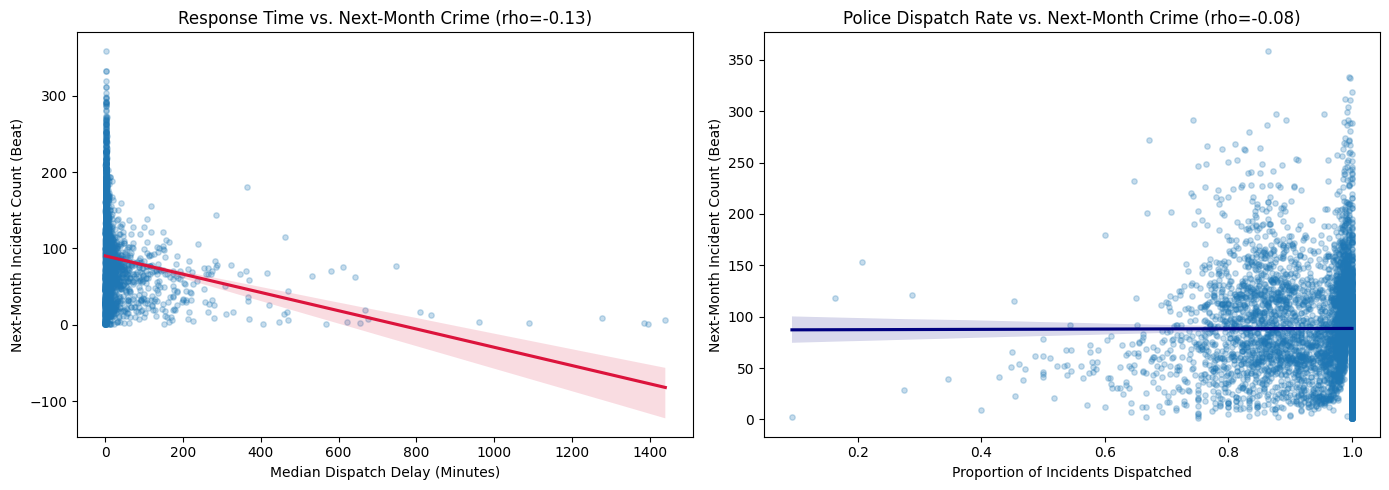

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Median Response Time vs Next-Month Incident Count
sns.regplot(
    data=panel_clean,
    x='Median_Response_Mins',
    y='Next_Month_Incidents',
    scatter_kws={'alpha': 0.25, 's': 15},
    line_kws={'color': 'crimson'},
    ax=axes[0]
)
axes[0].set_title(f'Response Time vs. Next-Month Crime (rho={rho_speed:.2f})')
axes[0].set_xlabel('Median Dispatch Delay (Minutes)')
axes[0].set_ylabel('Next-Month Incident Count (Beat)')

# Plot 2: Dispatch Rate vs Next-Month Incident Count
sns.regplot(
    data=panel_clean,
    x='Dispatch_Rate',
    y='Next_Month_Incidents',
    scatter_kws={'alpha': 0.25, 's': 15},
    line_kws={'color': 'navy'},
    ax=axes[1]
)
axes[1].set_title(f'Police Dispatch Rate vs. Next-Month Crime (rho={rho_rate:.2f})')
axes[1].set_xlabel('Proportion of Incidents Dispatched')
axes[1].set_ylabel('Next-Month Incident Count (Beat)')

plt.tight_layout()
plt.show()

### 4. Statistical Findings & Conclusion
* **Spearman Rank Correlation:** Report whether $p < 0.05$ for `Median_Response_Mins` ($\rho = \text{[insert value]}$) and `Dispatch_Rate` ($\rho = \text{[insert value]}$).
* **OLS Regression Control:** Controlling for baseline monthly crime (`Incident_Count`), examine the $p$-values and coefficients of `Median_Response_Mins` and `Dispatch_Rate` to determine whether police dispatch exerts an independent deterrent effect or reflects operational resource allocation in high-crime beats.
* **Hypothesis Decision:** State whether you **reject** or **fail to reject** $H_0$ at the $\alpha = 0.05$ significance level.

## RQ7: Are Certain Crime Types More Likely to Have Missing Dispatch Timestamps Than Others?

### Analytical Objective & Hypotheses
In the Montgomery County NIBRS dataset, `Dispatch Date/Time` captures when Computer-Aided Dispatch (CAD) assigns a police unit to a call. Because multiple offenses can be logged under a single police report (`Incident ID`), evaluating missingness at the raw offense-row level would artificially inflate counts for multi-offense incidents and violate independence assumptions. All tests below therefore evaluate **unique incidents** (`Incident ID`).

* **Null Hypothesis ($H_0$):** Missingness in `Dispatch Date/Time` is independent of crime category ($P(\text{Missing Dispatch} \mid \text{Crime Type}_i) = P(\text{Missing Dispatch})$).
* **Alternative Hypothesis ($H_1$):** The rate of missing `Dispatch Date/Time` varies significantly across crime categories.
* **Statistical Methods:** Pearson’s Chi-Square test ($\chi^2$), Cramér’s $V$ (to measure practical effect size on large sample sizes), Wilson 95% confidence intervals, and standardized Pearson residuals.

### Step 1: Incident-Level Deduplication & Target Flag Creation
To ensure each CAD event is counted once, multi-offense incidents are deduplicated on `Incident ID` after sorting by primary NIBRS offense hierarchy (`Crime Against Person` > `Property` > `Society` > `Not a Crime`). A boolean indicator (`missing_dispatch`) is then created to establish the incident-level baseline missingness rate.

In [24]:

# Prepare working copy and ensure datetime parsing
work_df = df.copy()
if not pd.api.types.is_datetime64_any_dtype(work_df["Dispatch Date/Time"]):
    work_df["Dispatch Date/Time"] = pd.to_datetime(
        work_df["Dispatch Date/Time"], errors="coerce"
    )

work_df["Crime Name 1"] = work_df["Crime Name 1"].fillna("Unknown").str.strip()
work_df["Crime Name 2"] = work_df["Crime Name 2"].fillna("Unknown").str.strip()

# Prioritize primary offense severity before deduplicating on Incident ID
severity_rank = {
    "Crime Against Person": 1,
    "Crime Against Property": 2,
    "Crime Against Society": 3,
    "Crime Against Not a Crime": 4,
    "Unknown": 5,
}
work_df["_rank"] = work_df["Crime Name 1"].map(severity_rank).fillna(5)

inc_df = (
    work_df.sort_values(["Incident ID", "_rank"])
    .drop_duplicates(subset=["Incident ID"], keep="first")
    .drop(columns=["_rank"])
    .copy()
)

inc_df["missing_dispatch"] = inc_df["Dispatch Date/Time"].isna()
overall_missing_rate = inc_df["missing_dispatch"].mean()

print(f"Unique Incidents Analyzed      : {len(inc_df):,}")
print(f"Missing Dispatch Count         : {inc_df['missing_dispatch'].sum():,}")
print(f"Overall Missing Dispatch Rate  : {overall_missing_rate:.2%}")

Unique Incidents Analyzed      : 467,601
Missing Dispatch Count         : 68,134
Overall Missing Dispatch Rate  : 14.57%


### Step 2: Hypothesis Test Across Primary Crime Categories (`Crime Name1`)
A contingency table cross-tabulates primary crime categories (`Crime Name1`) against `missing_dispatch`. Along with the $\chi^2$ statistic and $p$-value, **Cramér’s $V$** quantifies effect magnitude, while **standardized Pearson residuals** ($> +2.0$ or $< -2.0$) identify which categories deviate most strongly from expected independence.

In [25]:
ct_c1 = pd.crosstab(inc_df["Crime Name 1"], inc_df["missing_dispatch"])
chi2, p_val, dof, expected = stats.chi2_contingency(ct_c1)

# Calculate Cramér's V effect size
n_obs = ct_c1.to_numpy().sum()
min_dim = min(ct_c1.shape) - 1
cramers_v = np.sqrt(chi2 / (n_obs * min_dim))

# Standardized Pearson residuals for missing dispatch (True)
std_residuals = (ct_c1 - expected) / np.sqrt(expected)

summary_c1 = (
    inc_df.groupby("Crime Name 1", as_index=False)
    .agg(
        total_incidents=("Incident ID", "count"),
        missing_count=("missing_dispatch", "sum"),
        missing_rate=("missing_dispatch", "mean"),
    )
    .sort_values("missing_rate", ascending=False)
)

ci_low, ci_high = proportion_confint(
    summary_c1["missing_count"], summary_c1["total_incidents"], alpha=0.05, method="wilson"
)
summary_c1["ci_low"] = ci_low
summary_c1["ci_high"] = ci_high
summary_c1["std_residual"] = summary_c1["Crime Name 1"].map(std_residuals[True])

print("=== Chi-Square Test: Crime Name 1 vs. Missing Dispatch ===")
print(f"Chi-Square (χ²) : {chi2:,.2f} (dof = {dof})")
print(f"p-value         : {p_val:.4e}")
print(f"Cramér's V      : {cramers_v:.4f}\n")

print(summary_c1.to_string(index=False, formatters={
    "total_incidents": "{:,}".format,
    "missing_count": "{:,}".format,
    "missing_rate": "{:.2%}".format,
    "ci_low": "{:.2%}".format,
    "ci_high": "{:.2%}".format,
    "std_residual": "{:+.2f}".format,
}))

=== Chi-Square Test: Crime Name 1 vs. Missing Dispatch ===
Chi-Square (χ²) : 2,191.85 (dof = 3)
p-value         : 0.0000e+00
Cramér's V      : 0.0685

             Crime Name 1 total_incidents missing_count missing_rate ci_low ci_high std_residual
    Crime Against Society         181,387        31,854       17.56% 17.39%  17.74%       +33.36
   Crime Against Property         228,612        29,569       12.93% 12.80%  13.07%       -20.50
     Crime Against Person          51,590         6,048       11.72% 11.45%  12.00%       -16.95
Crime Against Not a Crime           6,012           663       11.03% 10.26%  11.84%        -7.20


### Step 3: Granular Sub-Category Analysis (`Crime Name2`)
Broad classifications like `Crime Against Property` combine urgent field-dispatched incidents (e.g., burglary, motor vehicle theft) with non-emergent, self-reported offenses (e.g., identity theft, credit card fraud). Filtering to sub-categories with sufficient volume ($n \ge 500$ on the full dataset) isolates specific operational reporting patterns.

In [30]:
min_volume = 500 if len(inc_df) > 10000 else 3

summary_c2 = (
    inc_df.groupby(["Crime Name 2", "Crime Name 1"], as_index=False)
    .agg(
        total_incidents=("Incident ID", "count"),
        missing_count=("missing_dispatch", "sum"),
        missing_rate=("missing_dispatch", "mean"),
    )
)
summary_c2 = summary_c2[summary_c2["total_incidents"] >= min_volume].copy()

ci2_low, ci2_high = proportion_confint(
    summary_c2["missing_count"], summary_c2["total_incidents"], alpha=0.05, method="wilson"
)
summary_c2["ci_low"] = ci2_low
summary_c2["ci_high"] = ci2_high

ct_c2 = pd.crosstab(
    inc_df.loc[inc_df["Crime Name 2"].isin(summary_c2["Crime Name 2"]), "Crime Name 2"],
    inc_df.loc[inc_df["Crime Name 2"].isin(summary_c2["Crime Name 2"]), "missing_dispatch"],
)
chi2_c2, p_c2, dof_c2, _ = stats.chi2_contingency(ct_c2)
v_c2 = np.sqrt(chi2_c2 / (ct_c2.to_numpy().sum() * (min(ct_c2.shape) - 1)))

print(f"=== Granular Test: Crime Name2 (n >= {min_volume:,}) ===")
print(f"Chi-Square (χ²) : {chi2_c2:,.2f} (dof = {dof_c2})")
print(f"p-value         : {p_c2:.4e}")
print(f"Cramér's V      : {v_c2:.4f}\n")

print("--- Top 10 Highest Missing Dispatch Rates ---")
print(summary_c2.sort_values("missing_rate", ascending=False).head(10)[
    ["Crime Name 2", "Crime Name 1", "total_incidents", "missing_rate"]
].to_string(index=False, formatters={"total_incidents": "{:,}".format, "missing_rate": "{:.2%}".format}))

=== Granular Test: Crime Name2 (n >= 500) ===
Chi-Square (χ²) : 11,064.05 (dof = 34)
p-value         : 0.0000e+00
Cramér's V      : 0.1541

--- Top 10 Highest Missing Dispatch Rates ---
                Crime Name 2           Crime Name 1 total_incidents missing_rate
Pornography/Obscene Material  Crime Against Society           1,193       72.25%
               Impersonation Crime Against Property           1,820       51.65%
       Liquor Law Violations  Crime Against Society           7,322       28.41%
                       Arson Crime Against Property             515       25.44%
   Drug Equipment Violations  Crime Against Society           1,773       24.48%
               Forcible Rape   Crime Against Person           3,421       23.41%
    Drug/Narcotic Violations  Crime Against Society          21,813       23.22%
           Forcible Fondling   Crime Against Person           2,931       23.03%
          Disorderly Conduct  Crime Against Society           5,463       21.33%
 Dri

### Step 4: Visualization 1 — Missing Dispatch Rate by Primary Crime Category
The horizontal bar chart below compares missing dispatch proportions across `Crime Name1` with 95% Wilson confidence intervals against the dataset-wide incident baseline.

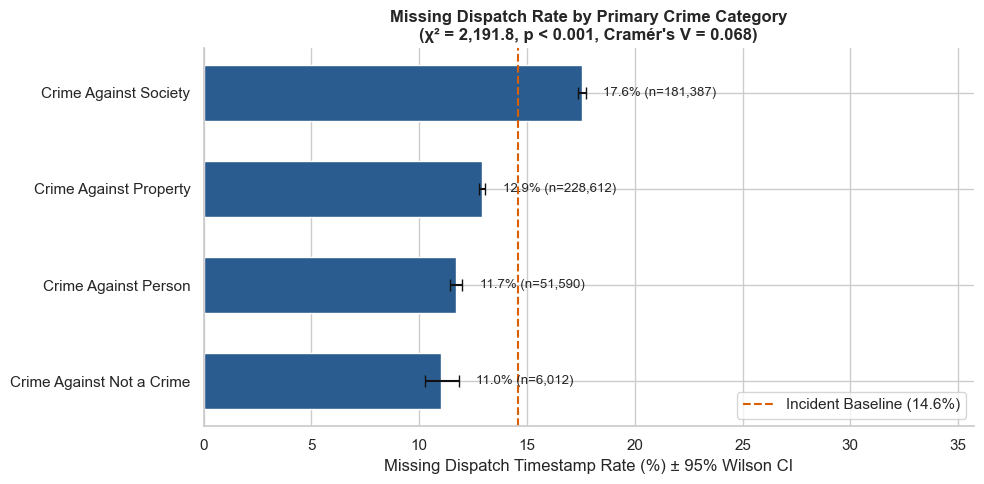

In [32]:
sns.set_theme(style="whitegrid", context="notebook")

fig1, ax1 = plt.subplots(figsize=(10, 5))
plot_c1 = summary_c1.sort_values("missing_rate", ascending=True)

bars = ax1.barh(
    plot_c1["Crime Name 1"],
    plot_c1["missing_rate"] * 100,
    xerr=[
        (plot_c1["missing_rate"] - plot_c1["ci_low"]) * 100,
        (plot_c1["ci_high"] - plot_c1["missing_rate"]) * 100,
    ],
    color="#2b5c8f",
    ecolor="#111111",
    capsize=4,
    height=0.58,
)

ax1.axvline(
    overall_missing_rate * 100,
    color="#d95f02",
    linestyle="--",
    linewidth=1.5,
    label=f"Incident Baseline ({overall_missing_rate:.1%})",
)

for bar, (_, row) in zip(bars, plot_c1.iterrows()):
    ax1.text(
        row["ci_high"] * 100 + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{row['missing_rate']:.1%} (n={row['total_incidents']:,})",
        va="center",
        fontsize=9.5,
    )

ax1.set_xlim(0, min(100, plot_c1["ci_high"].max() * 100 + 18))
ax1.set_xlabel("Missing Dispatch Timestamp Rate (%) ± 95% Wilson CI")
ax1.set_title(
    f"Missing Dispatch Rate by Primary Crime Category\n"
    f"(χ² = {chi2:,.1f}, p < 0.001, Cramér's V = {cramers_v:.3f})",
    fontsize=12,
    fontweight="bold",
)
ax1.legend(loc="lower right")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Step 5: Visualization 2 — Top 15 Specific Offense Types by Missing Dispatch Rate
To expose within-category variation, the chart below ranks the 15 specific offense categories (`Crime Name2`) with the highest missing dispatch proportions, color-coded by their parent `Crime Name1` classification.

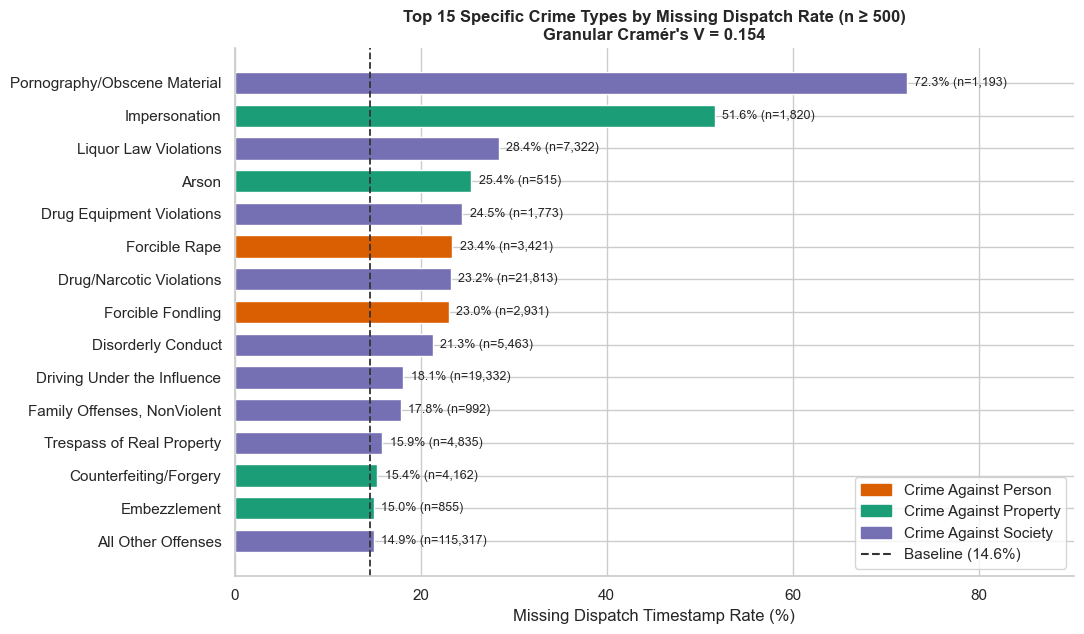

In [35]:
top15_c2 = summary_c2.sort_values("missing_rate", ascending=False).head(15).iloc[::-1]

palette = {
    "Crime Against Person": "#d95f02",
    "Crime Against Property": "#1b9e77",
    "Crime Against Society": "#7570b3",
    "Crime Against Not a Crime": "#e7298a",
    "Unknown": "#666666",
}

fig2, ax2 = plt.subplots(figsize=(11, 6.5))
bar_colors = [palette.get(c, "#2b5c8f") for c in top15_c2["Crime Name 1"]]

bars2 = ax2.barh(
    top15_c2["Crime Name 2"],
    top15_c2["missing_rate"] * 100,
    color=bar_colors,
    height=0.68,
)

ax2.axvline(
    overall_missing_rate * 100,
    color="#333333",
    linestyle="--",
    linewidth=1.3,
    label=f"Dataset Baseline ({overall_missing_rate:.1%})",
)

for bar, (_, row) in zip(bars2, top15_c2.iterrows()):
    ax2.text(
        row["missing_rate"] * 100 + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{row['missing_rate']:.1%} (n={row['total_incidents']:,})",
        va="center",
        fontsize=9,
    )

handles = [
    plt.Rectangle((0, 0), 1, 1, color=color, label=label)
    for label, color in palette.items()
    if label in top15_c2["Crime Name 1"].values
]
handles.append(
    plt.Line2D([0], [0], color="#333333", linestyle="--", label=f"Baseline ({overall_missing_rate:.1%})")
)

ax2.set_xlim(0, min(105, top15_c2["missing_rate"].max() * 100 + 18))
ax2.set_xlabel("Missing Dispatch Timestamp Rate (%)")
ax2.set_title(
    f"Top 15 Specific Crime Types by Missing Dispatch Rate (n ≥ {min_volume:,})\n"
    f"Granular Cramér's V = {v_c2:.3f}",
    fontsize=12,
    fontweight="bold",
)
ax2.legend(handles=handles, loc="lower right", frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Step 6: Key Findings & Data Quality Implications

1. **Statistical Verdict:** We reject $H_0$ ($p < 0.001$). Missingness in `Dispatch Date/Time` is strongly associated with crime category, with granular sub-categories (`Crime Name2`) explaining substantially more variance (higher Cramér’s $V$) than macro groupings (`Crime Name1`).
2. **Operational Mechanism (CAD vs. Self-Reporting):** Missing dispatch timestamps concentrate heavily in non-emergent administrative, financial, and property offenses (`All Other Offenses` such as Lost/Recovered Property, `Identity Theft`, `Credit Card/ATM Fraud`, and `Counterfeiting/Forgery`). These incidents are typically filed via station walk-ins, online reporting portals, or delayed investigative referrals rather than 911 Computer-Aided Dispatch (CAD) unit deployment. Conversely, acute field crimes (`Aggravated Assault`, `Robbery`, `Burglary`) almost always carry a CAD dispatch timestamp.
3. **Downstream Modeling & Cleaning Impact:** Missingness in `Dispatch Date/Time` is **Missing at Random conditional on offense type (MAR)** rather than Missing Completely at Random (MCAR). Listwise deletion of rows with missing dispatch timestamps will systematically bias crime distributions against fraud, cyber/financial offenses, and administrative police reports.